# NB11 — Rainfall-referenced assessment: methods audit, dependence-aware inference (R7), morphology and spectra (R8), rainfall dose–response (R9), submission figures

**Purpose.** Close the open analytical items of the manuscript using the saved NB09/NB10 outputs, run the approved protocol R7–R9, and rebuild all figures at 600 dpi (requirement ≥ 450 dpi).

**Reads (never modifies):** `results/mvp4_feasibility/` (NB09) and `results/mvp4_nb02/` (NB10); MVP-3 files `L2_land_adjacency_decay.json`, `D6_context_shares.json` (found under `results/`).
**Writes only to:** `results/mvp4_nb11/` (log, results JSON/CSV, arrays cache, figures as PDF + TIFF + PNG).

**Naming.** Drive folders keep their original names (`mvp4_feasibility`, `mvp4_nb02`, `mvp4_nb11`) so that saved paths and hashes remain valid; figures and manuscript use no internal project labels.

**Before the first run:** copy the approved protocol as `results/mvp4_nb11/R7_R9_protocol.md`. 2026 data are refused by a guard (untouched holdout).

| Section | Cells | Needs Earth Engine |
|---|---|---|
| A. Inputs and methods audit | NB11-00 … 04 | no |
| B. R7 dependence-aware inference | NB11-05 … 07 | no |
| C. R9 rainfall dose–response | NB11-08 | no |
| D. Figures 2, 3, 4, 5 | NB11-09 … 11 | no |
| E. Arrays, R7(c), R8, Figures 6, 7, 1 | NB11-12 … 18 | yes |
| F. Close-out | NB11-19 | no |

Run top to bottom. Earth Engine downloads are cached (`arrays/`, `spec_*.json`), so a restart resumes where it stopped.

## A. Inputs and methods audit

**NB11-00** — Setup: Drive, folders, helpers (log, atomic writes, hashes), figure export at 600 dpi. Earth Engine is initialised later, only in Section E.

In [1]:
# NB11-00 | Setup: Drive, folders, helpers (log, atomic writes, hashes), figure export at 600 dpi
import os, sys, json, time, hashlib, platform, itertools, math, datetime as dt
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats, ndimage
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
ROOT = os.environ.get('MPD_ROOT', '/content/drive/MyDrive/Marine_Plastic_Detection')
F1  = f'{ROOT}/results/mvp4_feasibility'      # NB09 outputs (read only)
F2  = f'{ROOT}/results/mvp4_nb02'             # NB10 outputs (read only)
OUT = f'{ROOT}/results/mvp4_nb11'             # NB11 outputs (this notebook writes only here)
FIG = f'{OUT}/figures'; ARR = f'{OUT}/arrays'
for d in (OUT, FIG, ARR): os.makedirs(d, exist_ok=True)
LOG = f'{OUT}/mvp4_nb11_log.json'
UTC = lambda: dt.datetime.now(dt.timezone.utc)
def hb(msg): print(f'[{UTC():%H:%M:%S}Z] {msg}', flush=True)
def read_json(p, default=None): return json.load(open(p)) if os.path.exists(p) else default
def write_json(p, obj):
    tmp = p + '.tmp'
    with open(tmp, 'w') as f: json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, p)
def write_csv(p, df): tmp = p + '.tmp'; df.to_csv(tmp, index=False); os.replace(tmp, p)
def log_event(key, obj):
    L = read_json(LOG, {}); L[key] = {**obj, 'utc': UTC().isoformat(timespec='seconds')}; write_json(LOG, L)
def sha(p): return hashlib.sha256(open(p, 'rb').read()).hexdigest()
def need(p):
    if not os.path.exists(p): raise FileNotFoundError(f'Required input missing: {p}')
    return p
DPI = 600                                     # submission requirement: >= 450 dpi
mpl.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'Liberation Serif', 'STIXGeneral', 'DejaVu Serif'], 'mathtext.fontset': 'stix', 'font.size': 8,
                     'axes.titlesize': 8, 'axes.labelsize': 8, 'legend.fontsize': 7, 'xtick.labelsize': 7,
                     'ytick.labelsize': 7, 'axes.linewidth': 0.6, 'savefig.dpi': DPI})
COL1, COL2 = 3.5, 7.16                        # IEEE single / double column width (inches)
def save_fig(fig, name):
    """Save PDF (vector), TIFF (LZW) and PNG at DPI; return paths."""
    paths = []
    for ext, kw in (('pdf', {}), ('tiff', {'pil_kwargs': {'compression': 'tiff_lzw'}}), ('png', {})):
        p = f'{FIG}/{name}.{ext}'; fig.savefig(p, dpi=DPI, bbox_inches='tight', **kw); paths.append(p)
    hb(f'saved {name} (.pdf/.tiff/.png, {DPI} dpi)'); return paths
SITES = {'guanabara': [-43.30, -22.95, -43.00, -22.60], 'sao_sebastiao': [-45.90, -23.90, -45.30, -23.70],
         'ilha_grande': [-44.65, -23.35, -44.05, -22.90]}                    # identical to NB09/NB10
NAME = {'guanabara': 'Guanabara Bay', 'sao_sebastiao': 'São Sebastião', 'ilha_grande': 'Ilha Grande'}
SCOL = {'guanabara': '#1f77b4', 'sao_sebastiao': '#ff7f0e', 'ilha_grande': '#2ca02c'}
PERIOD = lambda y: 'explore' if y <= 2021 else ('buffer' if y == 2022 else 'confirm')
LAST_YEAR = 2025                              # 2026 is the untouched holdout
def guard(d):
    if pd.Timestamp(d).year > LAST_YEAR: raise RuntimeError(f'{d}: 2026+ is the protected holdout; refused.')
FOOT = 'FDI anomalies only; no material identification.'
log_event(f'env_{UTC():%Y%m%dT%H%M%S}', {'python': platform.python_version(), 'numpy': np.__version__,
          'pandas': pd.__version__, 'scipy': __import__('scipy').__version__, 'matplotlib': mpl.__version__})
hb(f'NB11-00 ready | ROOT = {ROOT}')

Mounted at /content/drive
[11:21:27Z] NB11-00 ready | ROOT = /content/drive/MyDrive/Marine_Plastic_Detection


**NB11-01** — Protocol registration (R7–R9). Requires the approved protocol file in the NB11 folder; records its SHA-256, the approval date and the data seen. Runs once; later runs only verify the hash.

In [2]:
# NB11-01 | Protocol registration (R7–R9)
PROTOCOL = f'{OUT}/R7_R9_protocol.md'          # copy the approved protocol here (same text as deposited)
APPROVED_UTC = '2026-09-28'                    # team approval date
ZENODO_DOI = ''                                # fill in after deposit; kept in the log
need(PROTOCOL)
L = read_json(LOG, {})
if 'R7_R9_registered' not in L:
    log_event('R7_R9_registered', {
        'protocol_sha256': sha(PROTOCOL), 'approved': APPROVED_UTC, 'zenodo_doi': ZENODO_DOI,
        'what': 'R7 dependence-aware inference (clusters of shared references and storms, within-cluster permutation); '
                'R8 morphology and spectral description of exceedances; R9 rainfall dose-response (descriptive).',
        'why': 'Pair-level tests assume independent pairs; the visual reading is AI-proposed; rain link not yet quantified.',
        'data_seen': 'All rainfall-referenced results files and five quicklooks (NB10). No 2026 data. No R7-R9 output.'})
    hb('protocol registered')
else:
    assert L['R7_R9_registered']['protocol_sha256'] == sha(PROTOCOL), 'Protocol file changed after registration!'
    if ZENODO_DOI and not L['R7_R9_registered'].get('zenodo_doi'):
        L['R7_R9_registered']['zenodo_doi'] = ZENODO_DOI; write_json(LOG, L)
    hb('protocol hash verified')

[11:21:27Z] protocol hash verified


**NB11-02** — Load saved inputs and check integrity: pair table, per-date statistics (statsF), logs. Re-derives every ΔS from the statsF files and checks the counts, the 2,500-pixel rule and the storm counts against the NB09 log.

In [4]:
# NB11-02 | Load saved inputs and check integrity: pair table, per-date statistics (statsF), logs
PC = pd.read_csv(need(f'{F2}/pair_contrasts_full.csv'))
LOG1, LOG2 = read_json(need(f'{F1}/mvp4_log.json')), read_json(need(f'{F2}/mvp4_nb02_log.json'))
Q = LOG2['D-M4-3']['params']                  # NB10 parameters as logged
for d in pd.concat([PC.event, PC.ref]): guard(d)
U = PC[PC.used].copy().reset_index(drop=True)
assert len(U) == len(PC) == 77, f'expected 77 used pairs, got {len(U)} of {len(PC)}'
# 1) re-derive dS and src_ref from the per-date statistics
SF = {}
for s, d in {(r.site, x) for r in PC.itertuples() for x in (r.event, r.ref)}:
    SF[(s, d)] = read_json(need(f'{F2}/statsF_{s}_{d}.json'))
chk = []
for r in U.itertuples():
    E, R = SF[(r.site, r.event)], SF[(r.site, r.ref)]
    chk.append((abs(E['src']['exc_mean'] - R['src']['exc_mean'] - r.dS), abs(R['src']['exc_mean'] - r.src_ref)))
chk = np.array(chk); assert chk.max() < 1e-12, f'dS mismatch {chk.max()}'
# 2) the 2,500-pixel rule: valid pixel counts per zone and date (exc_count = valid pixels in the zone)
PX = pd.DataFrame([{'site': s, 'date': d, 'src_px': v['src'].get('exc_count', 0), 'far_px': v['far'].get('exc_count', 0),
                    'ok': v['ok']} for (s, d), v in SF.items()])
PX_SUM = {'dates': len(PX), 'dates_failing_rule': int((~PX.ok).sum()), 'min_src_px': int(PX.src_px.min()),
          'min_far_px': int(PX.far_px.min()), 'rule': 'date valid if src and far zones each have >= 2,500 valid 20 m pixels; '
          'pair used if both dates valid'}
# 3) storms: NB09 rule (chain of events with gaps <= storm_gap_d) must reproduce the logged counts
GAP = LOG1['feasibility_verdict_p90']['params']['storm_gap_d']
def storm_ids(events, gap=GAP):
    e = pd.Series(sorted(pd.to_datetime(pd.Series(events).unique())))
    sid = (e.diff().dt.days.fillna(gap + 1) > gap).cumsum()
    return dict(zip(e.dt.strftime('%Y-%m-%d'), sid))
U['storm'] = [f'{s}:{storm_ids(U.loc[U.site == s, "event"])[e]}' for s, e in zip(U.site, U.event)]
U['S_ev'], U['S_ref'] = U.dS + U.src_ref, U.src_ref
ver = LOG1['feasibility_verdict_p90']['verdict']
for s in SITES:
    u = U[U.site == s]; st = u.drop_duplicates('storm')
    for per, key in (('explore', 'storms_explore'), ('confirm', 'storms_confirm')):
        n = int((st.event.str[:4].astype(int).map(PERIOD) == per).sum())
        assert n == ver[s][key], f'{s} {per}: storms {n} != logged {ver[s][key]}'
hb(f'inputs OK | pairs {U.groupby("site").size().to_dict()} | dS re-derived (max err {chk.max():.1e}) | '
   f'storms match NB09 log | 2,500-px rule: {PX_SUM}')
log_event('inputs_check', {'pairs': U.groupby('site').size().to_dict(), 'px_rule': PX_SUM,
          'sha256': {'pair_contrasts_full.csv': sha(f'{F2}/pair_contrasts_full.csv')}})

[11:22:57Z] inputs OK | pairs {'guanabara': 23, 'ilha_grande': 24, 'sao_sebastiao': 30} | dS re-derived (max err 9.7e-17) | storms match NB09 log | 2,500-px rule: {'dates': 134, 'dates_failing_rule': 0, 'min_src_px': 73046, 'min_far_px': 252591, 'rule': 'date valid if src and far zones each have >= 2,500 valid 20 m pixels; pair used if both dates valid'}


**NB11-03** — Methods audit: reproduce the reported pair-level statistics from the saved table (Wilcoxon method, sign test, sign-flip count) and print the NB09/NB10 parameters that close the open Methods items.

In [ ]:
# NB11-03 | Methods audit: reproduce the reported pair-level statistics from the saved table (Wilcoxon method, sign test, sign-flip count) and print the NB09/NB10 parameters that close the open Methods items
RFS = read_json(need(f'{F2}/results_full_span.json'))
AUD = {}
for s in SITES:
    x = U.loc[U.site == s, 'dS'].values; nz = x[x != 0]
    p_ex = stats.wilcoxon(nz, alternative='greater', method='exact').pvalue
    p_ap = stats.wilcoxon(nz, alternative='greater', method='approx').pvalue
    AUD[s] = {'reported': RFS['per_site'][s]['wilcoxon_p_1s'], 'exact': round(float(p_ex), 4),
              'normal_approx': round(float(p_ap), 4), 'zeros_dropped': int((x == 0).sum()),
              'sign_p': round(float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue), 4)}
    assert abs(AUD[s]['exact'] - AUD[s]['reported']) < 1e-4, f'{s}: reported p is not the exact Wilcoxon'
p_expl = LOG2['exploratory_tests_far']['pooled']['signflip_p_1s']
AUD['signflip_flips'] = {'p_exploratory': p_expl, 'p_times_20001': round(p_expl * 20001, 6),
                         'consistent_with_20000': abs(p_expl * 20001 - round(p_expl * 20001)) < 1e-6}
P09 = LOG1['feasibility_verdict_p90']['params']
AUD['closed_items'] = {
    'CHIRPS': 'daily catchment mean (ee.Reducer.mean over HydroSHEDS catchment, scale 5566 m); 72 h = rolling 3-day sum',
    'percentile_base': 'all days 2019-01-01..2025-12-31 of the 72 h series (dry days included)',
    'event_trigger': f"heaviest 72 h window ending {P09['lags_d']} days before the overpass >= site p{P09['rain_pct']}",
    'reference': f"nearest clear dry date within +/-{P09['ref_window_d']} d; dry = 72 h < {P09['dry_r72_mm']} mm and "
                 f"7 d < {P09['dry_r7_mm']} mm, windows ending the day before",
    'clear': f"share of GSW>={P09['gsw_occ_min']} pixels in the site box with cs_cdf >= {P09['cs_thr']} (no score = not clear), "
             f"100 m; clear if >= {P09['clear_min']}",
    'storm': f'chain of events with consecutive gaps <= {GAP} d', 'min_zone_px': PX_SUM['rule'],
    'wilcoxon': 'scipy default = exact null distribution (n < 50, no ties); zero differences dropped',
    'signflip': '20,000 random sign vectors, p = (1 + count)/20,001, seed 0 (shared generator)',
    'GHSL': 'JRC/GHSL/P2023A/GHS_POP/2020, population_count summed at 100 m'}
log_event('methods_audit', AUD)
print(json.dumps(AUD, indent=1, ensure_ascii=False))

**NB11-04** — Sun-glint convention check. Recomputes the glint angle from the saved scene angles (geom_*.json) under both azimuth conventions and applies the pre-declared rule to each. If both give the same verdict, the convention does not affect the conclusion.

In [ ]:
# NB11-04 | Sun-glint convention check
ANG = ('MEAN_SOLAR_ZENITH_ANGLE', 'MEAN_SOLAR_AZIMUTH_ANGLE', 'MEAN_INCIDENCE_ZENITH_ANGLE_B8', 'MEAN_INCIDENCE_AZIMUTH_ANGLE_B8')
def glint(g, flip=False):
    ts, tv = np.radians(g[ANG[0]]), np.radians(g[ANG[2]])
    dphi = np.radians(g[ANG[1]] - g[ANG[3]] + (180.0 if flip else 0.0))
    return float(np.degrees(np.arccos(np.clip(np.cos(ts) * np.cos(tv) - np.sin(ts) * np.sin(tv) * np.cos(dphi), -1, 1))))
G = U[U.site == 'guanabara'].copy().reset_index(drop=True)
GEO = {d: read_json(need(f'{F2}/geom_guanabara_{d}.json')) for d in pd.concat([G.event, G.ref]).unique()}
GL = {}
for conv, flip in (('A_as_NB10', False), ('B_view_azimuth_plus_180', True)):
    ge = np.array([glint(GEO[d], flip) for d in G.event]); gr = np.array([glint(GEO[d], flip) for d in G.ref])
    G[f'glint_ev_{conv[0]}'], G[f'dglint_{conv[0]}'] = ge, ge - gr
    r1, r2, med = stats.spearmanr(G.dS, ge)[0], stats.spearmanr(G.dS, ge - gr)[0], float(np.median(ge))
    GL[conv] = {'spearman_dS_glint_event': round(float(r1), 3), 'spearman_dS_dglint': round(float(r2), 3),
                'median_deg': round(med, 1), 'min_deg': round(float(ge.min()), 1), 'max_deg': round(float(ge.max()), 1),
                'suspect': bool(r1 <= -0.5 or r2 <= -0.5 or med < 25)}
old = pd.read_csv(need(f'{F2}/guanabara_pairs_glint.csv'))
assert np.allclose(np.sort(old.glint_ev), np.sort(G.glint_ev_A), atol=1e-6), 'convention A does not reproduce NB10'
GL['verdict_depends_on_convention'] = GL['A_as_NB10']['suspect'] != GL['B_view_azimuth_plus_180']['suspect']
write_csv(f'{OUT}/glint_both_conventions.csv', G[['event', 'ref', 'dS', 'glint_ev_A', 'dglint_A', 'glint_ev_B', 'dglint_B']])
log_event('glint_conventions', GL); print(json.dumps(GL, indent=1))

## B. R7 — dependence-aware inference

**NB11-05** — R7, step 1: dependency graph per site. Nodes are dates; edges join each event to its reference and events of the same storm. Connected components are the independent clusters. Each date must carry a single S value.

In [ ]:
# NB11-05 | R7, step 1: dependency graph per site
def clusters(u, storm_links=True):
    """Return list of clusters; each = dict(nodes=[dates], values=np.array, w=np.array, pairs=int)."""
    val = {}
    for r in u.itertuples():
        for d, v in ((r.event, r.S_ev), (r.ref, r.S_ref)):
            assert d not in val or abs(val[d] - v) < 1e-12, f'date {d} has two different S values'
            val[d] = v
    par = {d: d for d in val}
    def find(a):
        while par[a] != a: par[a] = par[par[a]]; a = par[a]
        return a
    def join(a, b): par[find(a)] = find(b)
    for r in u.itertuples(): join(r.event, r.ref)
    if storm_links:
        for _, g in u.groupby('storm'):
            ev = list(g.event.unique())
            for a, b in zip(ev, ev[1:]): join(a, b)
    comp = {}
    for d in val: comp.setdefault(find(d), []).append(d)
    out = []
    for nodes in comp.values():
        nodes = sorted(nodes); idx = {d: i for i, d in enumerate(nodes)}
        w = np.zeros(len(nodes))                       # weight: +1 per pair as event, -1 per pair as reference
        sub = u[u.event.isin(nodes)]
        for r in sub.itertuples(): w[idx[r.event]] += 1; w[idx[r.ref]] -= 1
        out.append({'nodes': nodes, 'values': np.array([val[d] for d in nodes]), 'w': w, 'pairs': len(sub)})
    return out
CL = {s: clusters(U[U.site == s]) for s in SITES}
CL_REF = {s: clusters(U[U.site == s], storm_links=False) for s in SITES}
rows = []
for s in SITES:
    for k, c in enumerate(CL[s]):
        for d in c['nodes']: rows.append({'site': s, 'cluster': k, 'date': d, 'cluster_dates': len(c['nodes']), 'cluster_pairs': c['pairs']})
CLT = pd.DataFrame(rows); write_csv(f'{OUT}/r7_clusters.csv', CLT)
U['cluster'] = [f"{s}:{CLT[(CLT.site == s) & (CLT.date == e)].cluster.iloc[0]}" for s, e in zip(U.site, U.event)]
for s in SITES:
    sz = sorted([c['pairs'] for c in CL[s]], reverse=True)
    hb(f'{NAME[s]}: {len(CL[s])} clusters (ref-only: {len(CL_REF[s])}); pairs per cluster {sz}')

**NB11-06** — R7, step 2: within-cluster permutation test (exact when the number of arrangements is ≤ 1,000,000, otherwise 100,000 Monte Carlo permutations with a dedicated generator, seed 0). Statistic: mean ΔS per site; pooled: mean of the three site means.

In [ ]:
# NB11-06 | R7, step 2: within-cluster permutation test (exact when the number of arrangements is ≤ 1,000,000, otherwise 100,000 Monte Carlo permutations with a dedicated generator, seed 0)
MAX_EXACT, B_MC = 1_000_000, 100_000
def cluster_contribs(c):
    """All values of sum_j w_j * v_perm(j) over permutations of the cluster's values (with multiplicity)."""
    return np.array([np.dot(c['w'], p) for p in itertools.permutations(c['values'])])
def exact_dist(cl):
    dist = np.array([0.0])
    for c in cl: dist = (dist[:, None] + cluster_contribs(c)[None, :]).ravel()
    return dist
def mc_contrib(cl, rng, B):
    tot = np.zeros(B)
    for c in cl:
        n = len(c['values'])
        if n == 1: continue
        perm = np.argsort(rng.random((B, n)), axis=1)
        tot += c['values'][perm] @ c['w']
    return tot
def min_p(cl):
    f = 1.0
    for c in cl:
        if len(c['values']) > 9: return np.nan
        v = cluster_contribs(c); f *= np.mean(v >= v.max() - 1e-12)
    return f
def r7_site(cl):
    npairs = sum(c['pairs'] for c in cl); obs = sum(np.dot(c['w'], c['values']) for c in cl) / npairs
    n_arr = math.prod(math.factorial(len(c['values'])) for c in cl)
    if n_arr <= MAX_EXACT:
        d = exact_dist(cl) / npairs; p = float(np.mean(d >= obs - 1e-12)); how = f'exact ({n_arr} arrangements)'
    else:
        d = mc_contrib(cl, np.random.default_rng(0), B_MC) / npairs
        p = float((1 + np.sum(d >= obs - 1e-12)) / (1 + B_MC)); how = f'Monte Carlo B={B_MC} (arrangements {n_arr:.2e})'
    return {'n_pairs': npairs, 'n_clusters': len(cl), 'mean_dS': round(float(obs), 5), 'p_1s': round(p, 5),
            'method': how, 'min_attainable_p': (float(f'{min_p(cl):.3g}') if not np.isnan(min_p(cl)) else None)}
def r7_pooled(CLd):
    rng = np.random.default_rng(0)
    obs = np.mean([sum(np.dot(c['w'], c['values']) for c in CLd[s]) / sum(c['pairs'] for c in CLd[s]) for s in SITES])
    null = np.mean([mc_contrib(CLd[s], rng, B_MC) / sum(c['pairs'] for c in CLd[s]) for s in SITES], axis=0)
    return {'mean_of_site_means': round(float(obs), 5), 'p_1s': round(float((1 + np.sum(null >= obs - 1e-12)) / (1 + B_MC)), 5),
            'method': f'Monte Carlo B={B_MC}'}
R7 = {'primary_and_secondary': {s: r7_site(CL[s]) for s in SITES} | {'pooled': r7_pooled(CL)},
      'sensitivity_a_reference_links_only': {s: r7_site(CL_REF[s]) for s in SITES} | {'pooled': r7_pooled(CL_REF)}}
print(json.dumps(R7, indent=1))

**NB11-07** — R7, step 3: sensitivity (b), an independent subset (one pair per reference date, then one per storm; smallest event–reference gap, ties to the earliest event) tested with the exact one-sided Wilcoxon and sign tests. Saves R7 results.

In [ ]:
# NB11-07 | R7, step 3: sensitivity (b), an independent subset (one pair per reference date, then one per storm; smallest event–reference gap, ties to the earliest event) tested with the exact one-sided Wilcoxon and sign tests
def independent_subset(u):
    u = u.assign(gap=(pd.to_datetime(u.event) - pd.to_datetime(u.ref)).dt.days.abs())
    u = u.sort_values(['gap', 'event']).drop_duplicates('ref')
    return u.sort_values(['gap', 'event']).drop_duplicates('storm').sort_values('event')
SUB = {}
for s in SITES:
    u = independent_subset(U[U.site == s]); x = u.dS.values; nz = x[x != 0]
    SUB[s] = {'n_pairs': len(u), 'median_dS': round(float(np.median(x)), 4), 'n_pos': int((x > 0).sum()),
              'wilcoxon_exact_p_1s': round(float(stats.wilcoxon(nz, alternative='greater', method='exact').pvalue), 4),
              'sign_p_1s': round(float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue), 4)}
R7['sensitivity_b_independent_subset'] = SUB
R7['descriptive_pair_level'] = {s: {'wilcoxon_exact_p_1s': AUD[s]['exact'], 'note': 'assumes independent pairs'} for s in SITES}
R7['rules'] = {'statistic': 'mean dS per site; pooled = mean of site means', 'null': 'S values exchangeable among the dates '
               'of each cluster; clusters independent', 'clusters': 'connected components of event-reference and same-storm links'}
write_json(f'{OUT}/r7_results.json', R7); log_event('R7_results', R7)
print(pd.DataFrame({s: {**R7['primary_and_secondary'][s], **{f'subset_{k}': v for k, v in SUB[s].items()}} for s in SITES}).T.to_string())

## C. R9 — rainfall dose–response

**NB11-08** — R9: rainfall dose–response (descriptive). Reads the cached CHIRPS catchment series (rain_*.json), applies the NB09 event definition to obtain each event's 72 h total, and reports Spearman ρ per site with a 95% CI from a bootstrap over R7 clusters (B = 2,000, seed 0).

In [ ]:
# NB11-08 | R9: rainfall dose–response (descriptive)
def load_rain(site):
    r = pd.concat([pd.DataFrame(read_json(need(f'{F1}/rain_{site}_{y}.json'))) for y in range(2019, 2026)])
    r['d'] = pd.to_datetime(r.d); r['mm'] = r.mm.where(r.mm >= 0)
    return r.drop_duplicates('d').set_index('d').mm.asfreq('D')
LAGS = LOG1['feasibility_verdict_p90']['params']['lags_d']
R72 = {}
for s in SITES:
    r72 = load_rain(s).rolling(3).sum()
    ev72 = pd.concat([r72.shift(L) for L in LAGS], axis=1).max(axis=1)          # identical to NB09 make_pairs
    R72[s] = ev72; thr = LOG1['feasibility_verdict_p90']['verdict'][s]['r72_p90_mm']
    e72 = ev72.reindex(pd.to_datetime(U.loc[U.site == s, 'event'])).values
    assert np.all(e72 >= thr - 0.05), f'{s}: an event is below the logged p90 ({thr} mm)'
U['r72_event_mm'] = [float(R72[s].loc[pd.Timestamp(e)]) for s, e in zip(U.site, U.event)]
R9, rng9 = {}, np.random.default_rng(0)
for s in SITES:
    u = U[U.site == s]; rho = stats.spearmanr(u.dS, u.r72_event_mm)[0]
    groups = [g for _, g in u.groupby('cluster')]; bs = []
    for _ in range(2000):
        b = pd.concat([groups[i] for i in rng9.integers(0, len(groups), len(groups))])
        if b.dS.nunique() > 2 and b.r72_event_mm.nunique() > 2: bs.append(stats.spearmanr(b.dS, b.r72_event_mm)[0])
    R9[s] = {'n': len(u), 'spearman_rho': round(float(rho), 3), 'ci95_cluster_boot': [round(float(np.nanpercentile(bs, q)), 3) for q in (2.5, 97.5)],
             'r72_event_mm_range': [round(float(u.r72_event_mm.min()), 1), round(float(u.r72_event_mm.max()), 1)]}
write_json(f'{OUT}/r9_results.json', R9); log_event('R9_results', R9)
write_csv(f'{OUT}/pairs_nb11.csv', U); print(json.dumps(R9, indent=1))

## D. Figures without Earth Engine

**NB11-09** — Figure 2 — workflow diagram at full two-column width (7.16 in on the page), text 7–8 pt at print size, with an automatic check that every label fits its box; exported by save_fig as vector PDF and 600 dpi TIFF/PNG.

In [ ]:
# NB11-09 | Figure 2 — workflow diagram at full two-column width (7.16 in on the page), text 7–8 pt at print size, with an automatic check that every label fits its box; exported by save_fig as vector PDF and 600 dpi TIFF/PNG
BOX_PT, HEAD_PT, NOTE_PT = 7.0, 8.0, 7.0                         # final print sizes (IEEE: legible at ~7–8 pt)
fig, ax = plt.subplots(figsize=(COL2 - 0.2, 3.0)); ax.set_xlim(-0.6, 100.9); ax.set_ylim(0, 46); ax.axis('off')   # +0.1 in padding per side in save_fig -> 7.16 in
fig.subplots_adjust(left=0.005, right=0.995, bottom=0.005, top=0.995)   # axes fill the full 7.16 in width (default margins would shrink it)
BW, BH, X0 = 18.4, 12.0, [0.6, 20.9, 41.2, 61.5, 81.8]          # box width/height and left edges (axis units)
def box(x, y, txt, fc):
    ax.add_patch(mpl.patches.FancyBboxPatch((x, y), BW, BH, boxstyle='round,pad=0.3,rounding_size=1.0', fc=fc, ec='0.25', lw=0.6, clip_on=False))
    return ax.text(x + BW / 2, y + BH / 2, txt, ha='center', va='center', fontsize=BOX_PT, linespacing=1.2)
def arrow(x0, y0, x1, y1): ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', lw=0.6, color='0.25', shrinkA=0, shrinkB=0))
def row(items, y, fc):
    txt = [box(x, y, t, fc) for t, x in zip(items, X0)]
    for xa, xb in zip(X0, X0[1:]): arrow(xa + BW + 0.4, y + BH / 2, xb - 0.4, y + BH / 2)
    return txt
ax.text(0.6, 43.8, '(a) Cross-sensor assessment — Ilha Grande Bay', fontsize=HEAD_PT, weight='bold', va='center')
T1 = row(['Sentinel-2 L2A FDI;\nanomalies above\ndate-specific p99', 'CBERS-4A WPM\nNIR − blue contrast\n(0–1 day later)',
          'GCOM-C SGLI\nbaseline index, LR$^+$\n(1 km and 250 m)', 'Open water\n(≥ 500 m from land);\nAUC in 1 km cells',
          'Pre-specified dates\nand trend test\n(5 of 449 eligible)'], 28.5, '#f2f2f2')
arrow(50, 27.6, 50, 22.4)
ax.text(51.5, 25.0, 'few coincident scenes; no open-water agreement', fontsize=NOTE_PT, style='italic', va='center')
ax.text(0.6, 20.3, '(b) Rainfall-referenced assessment — Guanabara Bay, São Sebastião, Ilha Grande', fontsize=HEAD_PT, weight='bold', va='center')
T2 = row(['CHIRPS 72 h rain\n≥ 90th percentile;\nlow-rainfall ref. ±30 d', 'River outlets\n(HydroSHEDS + OSM);\nsource ≤ 2 km,\nfar > 3 km',
          'Exceedance share S\nabove far-zone p99;\nΔS = event − ref.', 'Cluster-based\npermutation test\n(shared refs, storms)',
          'Checks: turbidity,\nglint, morphology,\nspectra, rain amount'], 5.0, '#e8f0f8')
ax.text(50, 1.2, 'Departures from pre-specified plans are logged (Table IV); 2026 imagery is withheld as an independent holdout.',
        ha='center', va='center', fontsize=NOTE_PT, style='italic')
# layout check: every box label must fit inside its box (fails loudly instead of producing clipped text)
fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transData.inverted()
for t in T1 + T2:
    bb = inv.transform(t.get_window_extent(r)); w = bb[1, 0] - bb[0, 0]; h = bb[1, 1] - bb[0, 1]
    assert w <= BW - 0.3 and h <= BH - 0.3, f'label does not fit its box: {t.get_text()!r} ({w:.1f} x {h:.1f})'
FIG2 = save_fig(fig, 'fig2_workflow'); plt.show(); plt.close(fig)

**NB11-10** — Figure 3 — land adjacency at Ilha Grande (cross-sensor assessment), single-column layout (3.5 in wide, 8 pt text): (a) within-cell AUC by distance to land with 95% CIs; (b) share of FDI anomalies vs all water within 100 m of non-water. Locates the saved cross-sensor result files under ROOT.

In [ ]:
# NB11-10 | Figure 3 — land adjacency at Ilha Grande (cross-sensor assessment), single-column layout (3.5 in wide, 8 pt text): (a) within-cell AUC by distance to land with 95% CIs; (b) share of FDI anomalies vs all water within 100 m of non-water
def find_file(name, base=f'{ROOT}/results'):
    for dp, _, fs in os.walk(base):
        if name in fs: return os.path.join(dp, name)
    raise FileNotFoundError(f'{name} not found under {base}; set its path manually')
L2P, D6P = find_file('L2_land_adjacency_decay.json'), find_file('D6_context_shares.json')
L2, D6 = read_json(L2P), read_json(D6P)
BINS = ['0–200', '200–500', '500–1000', '>1000']
with mpl.rc_context({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7.5,
                     'ytick.labelsize': 7.5, 'legend.fontsize': 7}):
    fig, (a, b) = plt.subplots(2, 1, figsize=(COL1, 5.6), gridspec_kw={'height_ratios': [1.15, 1]})
    dates = [(d, 'primary', v) for d, v in L2['primary'].items()] + [(d, 'supplementary', v) for d, v in L2['supplementary'].items()]
    off = np.linspace(-0.27, 0.27, len(dates)); cm = plt.get_cmap('tab10')
    for k, (d, kind, rows) in enumerate(dates):
        xs, ys, lo, hi = [], [], [], []
        for i, r in enumerate(rows):
            if r.get('auc') is None: continue
            xs.append(i + off[k]); ys.append(r['auc']); lo.append(r['auc'] - r['auc_ci'][0]); hi.append(r['auc_ci'][1] - r['auc'])
        a.errorbar(xs, ys, yerr=[lo, hi], fmt='o', ms=3.6, mfc=cm(k) if kind == 'primary' else 'white', mec=cm(k),
                   ecolor=cm(k), elinewidth=0.7, capsize=1.5, mew=0.8, label=d)
    a.axhline(0.5, color='0.4', lw=0.7, ls='--'); a.text(-0.45, 0.49, 'no agreement', fontsize=6.5, ha='left', va='top', color='0.35')
    a.set_xticks(range(4)); a.set_xticklabels(BINS); a.set_xlim(-0.5, 3.5)
    a.set_xlabel('Distance to land (m)'); a.set_ylabel('Within-cell AUC'); a.set_ylim(0.3, 1.22); a.set_yticks(np.arange(0.3, 1.01, 0.1))
    a.set_title('(a) Sentinel-2 vs CBERS-4A agreement', loc='left')
    h, l = a.get_legend_handles_labels()
    a.legend(h, l, ncol=3, frameon=False, loc='upper center', handletextpad=0.1, columnspacing=0.6, fontsize=6.5,
             title='filled: primary dates; open: supplementary', title_fontsize=6.5)
    pd6 = D6['per_date']; ds = sorted(pd6); y = np.arange(len(ds)); hgt = 0.38
    b.barh(y - hgt / 2, [100 * pd6[d]['cand']['any'] for d in ds], hgt, color='#b2182b', label='FDI anomalies')
    b.barh(y + hgt / 2, [100 * pd6[d]['water']['any'] for d in ds], hgt, color='#9e9e9e', label='all water')
    b.set_yticks(y); b.set_yticklabels(ds); b.invert_yaxis(); b.set_xlim(0, 100)
    b.set_xlabel('Share within 100 m of non-water (%)')
    b.set_title('(b) Context of anomalies (whole scene)', loc='left'); b.legend(frameon=False, loc='lower right')
    fig.tight_layout(h_pad=1.2); FIG3 = save_fig(fig, 'fig3_adjacency'); plt.show(); plt.close(fig)
log_event('fig3', {'inputs': {'L2': L2P, 'D6': D6P}, 'paths': FIG3, 'layout': 'single column 3.5 in'})

**NB11-11** — Figures 4 and 5 — Fig. 4: the rainfall-referenced response (pair contrasts by site, Guanabara pairs as reference→event dumbbells, Guanabara by period); Fig. 5: robustness checks (turbidity, sun glint under both conventions, rainfall amount). Explicit legends for every colour and marker.

In [ ]:
# NB11-11 | Figures 4 and 5 — Fig
PER = [('explore', '2019–21 (exploratory)', '#4c72b0'), ('buffer', '2022 (buffer)', '#9e9e9e'), ('confirm', '2023–25', '#c44e52')]
PCOL = {k: c for k, _, c in PER}; jit = np.random.default_rng(1)
H = lambda **kw: mpl.lines.Line2D([], [], **kw)                               # legend handle helper
# ---------- Figure 4: the response ----------
fig, (a, b, c) = plt.subplots(1, 3, figsize=(COL2, 3.1), gridspec_kw={'width_ratios': [1.25, 1.1, 0.85]})
# (a) pair contrasts per site: each dot is one event–reference pair
for i, s in enumerate(SITES):
    u = U[U.site == s]
    a.scatter(i + jit.uniform(-0.17, 0.17, len(u)), u.dS, s=7, c=u.period.map(PCOL), lw=0, alpha=0.9, zorder=2)
    med, ci = RFS['per_site'][s]['median_dS'], RFS['per_site'][s]['ci95_clustered']
    a.errorbar(i + 0.32, med, yerr=[[med - ci[0]], [ci[1] - med]], fmt='D', ms=3.5, color='k', elinewidth=0.8, capsize=2, zorder=3)
a.axhline(0, color='0.5', lw=0.5, zorder=1); a.set_xticks(range(3)); a.set_xlim(-0.5, 2.6)
a.set_xticklabels([f"{NAME[s].replace(' ', chr(10), 1) if s == 'guanabara' else NAME[s].replace(' ', chr(10))}\n"
                   f"{R7['primary_and_secondary'][s]['n_pairs']} pairs\np$_{{\\rm perm}}$ = {R7['primary_and_secondary'][s]['p_1s']:.3f}"
                   for s in SITES], fontsize=6)
a.set_ylabel('ΔS = S$_{\\rm event}$ − S$_{\\rm reference}$')
a.set_title('(a) Change in exceedance share, by site', loc='left')
lo_, hi_ = a.get_ylim(); a.set_ylim(lo_, hi_ + 0.35 * (hi_ - lo_))
a.legend(handles=[H(ls='', marker='o', ms=3, color=col, label=lab) for _, lab, col in PER] +
         [H(ls='', marker='D', ms=3, color='k', label='median, 95% CI')], frameon=False, fontsize=5.5, loc='upper left', ncol=2,
         handletextpad=0.2, columnspacing=0.6)
# (b) Guanabara: every pair as a dumbbell, sorted by change (reference = open, event = filled)
g = U[U.site == 'guanabara'].sort_values('dS').reset_index(drop=True); y = np.arange(len(g))
for k, r in g.iterrows():
    colr = '#c44e52' if r.dS > 0 else '#4c72b0'
    b.plot([100 * r.S_ref, 100 * r.S_ev], [k, k], color=colr, lw=0.9, zorder=1)
    b.scatter(100 * r.S_ref, k, s=9, facecolor='white', edgecolor=colr, lw=0.6, zorder=2)
    b.scatter(100 * r.S_ev, k, s=9, color=colr, lw=0, zorder=3)
b.set_yticks([]); b.set_ylabel('Pairs, sorted by ΔS'); b.set_xlabel('Source-zone exceedance share S (%)')
npos = int((g.dS > 0).sum()); b.set_title(f'(b) Guanabara Bay: {npos} of {len(g)} pairs rise', loc='left')
b.legend(handles=[H(ls='', marker='o', ms=3, mfc='white', mec='0.3', label='low-rainfall reference'),
                  H(ls='', marker='o', ms=3, color='0.3', label='after heavy rain'),
                  H(color='#c44e52', lw=1, label='rise'), H(color='#4c72b0', lw=1, label='fall')],
         frameon=False, fontsize=5.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
# (c) Guanabara: change by period (effect smaller after the exploratory years)
for k, (p, lab, col) in enumerate(PER):
    v = g[g.period == p].dS
    c.scatter(k + jit.uniform(-0.12, 0.12, len(v)), v, s=7, color=col, lw=0)
    if len(v): c.plot([k - 0.25, k + 0.25], [v.median()] * 2, color='k', lw=1.1)
    c.text(k, 0.97, f'n = {len(v)}\nmed. {v.median():+.3f}', transform=mpl.transforms.blended_transform_factory(c.transData, c.transAxes),
           ha='center', va='top', fontsize=5.5)
c.axhline(0, color='0.5', lw=0.5); c.set_xticks(range(3)); c.set_xticklabels(['2019–21', '2022', '2023–25'])
lo_, hi_ = c.get_ylim(); c.set_ylim(lo_, hi_ + 0.3 * (hi_ - lo_))
c.set_ylabel('ΔS'); c.set_title('(c) Guanabara Bay, by period', loc='left')
fig.tight_layout(); FIG4 = save_fig(fig, 'fig4_response'); plt.show(); plt.close(fig)
# ---------- Figure 5: robustness checks at Guanabara Bay and rainfall dose–response ----------
fig, (d, e, f) = plt.subplots(1, 3, figsize=(COL2, 2.5))
d.scatter(g.did_b4 * 1e3, g.dS, s=8, color='0.25', lw=0, zorder=2)
bb = np.polyfit(g.did_b4 * 1e3, g.dS, 1); xx = np.linspace(g.did_b4.min() * 1e3, g.did_b4.max() * 1e3, 10)
d.plot(xx, np.polyval(bb, xx), color='#c44e52', lw=0.8, zorder=1); ai = RFS['pooled']['adj_guanabara']
d.errorbar(0, ai['intercept'], yerr=[[ai['intercept'] - ai['ci95_clustered'][0]], [ai['ci95_clustered'][1] - ai['intercept']]],
           fmt='s', ms=3.5, color='#c44e52', capsize=2, elinewidth=0.8, zorder=3)
d.axhline(0, color='0.5', lw=0.5); d.axvline(0, color='0.5', lw=0.5)
d.set_xlabel('ΔB4, turbidity proxy (×10$^{-3}$)'); d.set_ylabel('ΔS')
lo_, hi_ = d.get_ylim(); d.set_ylim(lo_, hi_ + 0.4 * (hi_ - lo_))
d.set_title(f"(a) Turbidity: ρ = {RFS['per_site']['guanabara']['spearman_dS_b4']:.2f}", loc='left')
d.legend(handles=[H(ls='', marker='o', ms=3, color='0.25', label='pairs'), H(color='#c44e52', lw=0.8, label='OLS fit'),
                  H(ls='', marker='s', ms=3, color='#c44e52', label=f"ΔS at ΔB4 = 0: {ai['intercept']:+.3f}")],
         frameon=False, fontsize=5.5, loc='upper right')
GG = pd.read_csv(f'{OUT}/glint_both_conventions.csv')
e.axvspan(min(15, GG[['glint_ev_A', 'glint_ev_B']].min().min() - 1), 25, color='0.92', lw=0)
e.scatter(GG.glint_ev_A, GG.dS, s=8, color='0.25', lw=0)
e.scatter(GG.glint_ev_B, GG.dS, s=8, facecolor='none', edgecolor='0.25', lw=0.5)
e.axhline(0, color='0.5', lw=0.5); e.set_xlabel('Sun-glint angle on event date (°)'); e.set_ylabel('ΔS')
lo_, hi_ = e.get_ylim(); e.set_ylim(lo_, hi_ + 0.45 * (hi_ - lo_))
both_ok = not (GL['A_as_NB10']['suspect'] or GL['B_view_azimuth_plus_180']['suspect'])
e.set_title('(b) Glint: ' + ('not suspect under either convention' if both_ok else 'suspect under at least one convention'), loc='left')
e.legend(handles=[H(ls='', marker='o', ms=3, color='0.25', label=f"azimuth convention A, ρ = {GL['A_as_NB10']['spearman_dS_glint_event']:+.2f}"),
                  H(ls='', marker='o', ms=3, mfc='none', mec='0.25', label=f"convention B, ρ = {GL['B_view_azimuth_plus_180']['spearman_dS_glint_event']:+.2f}"),
                  mpl.patches.Patch(color='0.92', label='< 25°: high glint risk')], frameon=False, fontsize=5.5, loc='upper right')
for s in SITES:
    u = U[U.site == s]; ci9 = R9[s]['ci95_cluster_boot']
    f.scatter(u.r72_event_mm, u.dS, s=7, color=SCOL[s], lw=0, alpha=0.9,
              label=f"{NAME[s]}: ρ = {R9[s]['spearman_rho']:+.2f} [{ci9[0]:+.2f}, {ci9[1]:+.2f}]")
f.axhline(0, color='0.5', lw=0.5); f.set_xlabel('72 h catchment rainfall before event (mm)'); f.set_ylabel('ΔS')
f.set_title('(c) Rainfall amount vs ΔS', loc='left'); f.legend(frameon=False, fontsize=5.2, loc='upper right', handletextpad=0.1)
lo_, hi_ = f.get_ylim(); f.set_ylim(lo_, hi_ + 0.3 * (hi_ - lo_))
fig.tight_layout(); FIG5 = save_fig(fig, 'fig5_robustness'); plt.show(); plt.close(fig)
log_event('fig4_fig5', {'fig4': FIG4, 'fig5': FIG5})

## E. Earth Engine: arrays, R7(c), R8, Figures 6, 7, 1

**NB11-12** — Section E setup (Earth Engine): reproduces the NB10 definitions exactly (collections, stable water, zones, FDI, validity mask) and the 20 m UTM grid used by NB10's reductions.

In [6]:
# NB11-12 | Section E setup (Earth Engine): reproduces the NB10 definitions exactly (collections, stable water, zones, FDI, validity mask) and the 20 m UTM grid used by NB10's reductions
import ee
EE_PROJECT = 'marplastdetection'
try: ee.Initialize(project=EE_PROJECT)
except Exception: ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
CSP = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
WATER = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').gte(Q['gsw_occ_min'])
def zone_image(site):                                            # identical to NB10 cell MVP4-22
    df = pd.read_csv(need(f'{F1}/outlets_merged_{site}.csv'))
    pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([float(x), float(y)])) for x, y in zip(df.lon, df.lat)])
    dist = pts.distance(searchRadius=Q['search_m']).unmask(Q['search_m'] + 1)
    zone = ee.Image(0).where(dist.lte(Q['zone_src_m']), 1).where(dist.gt(Q['zone_far_m']), 2)
    return zone.updateMask(WATER.And(zone.gt(0))).rename('zone').clip(ee.Geometry.Rectangle(SITES[site]))
ZONES = {s: zone_image(s) for s in SITES}
def scene(site, d):                                              # identical to NB10 date_stats_far
    guard(d); box = ee.Geometry.Rectangle(SITES[site]); d0 = ee.Date(d); d1 = d0.advance(1, 'day')
    s2 = S2.filterBounds(box).filterDate(d0, d1).mosaic()
    cs = CSP.filterBounds(box).filterDate(d0, d1).select('cs_cdf').mosaic()
    r = lambda b: s2.select(b).divide(1e4)
    fdi = r('B8').subtract(r('B6').add(r('B11').subtract(r('B6')).multiply(Q['fdi_w'] * 10))).rename('fdi')
    valid = (cs.lt(Q['cs_thr']).unmask(1).focalMax(Q['cloud_buf_m'], 'circle', 'meters').Not()
             .And(WATER).And(s2.select('B8').mask().gt(0)))
    return s2, fdi, valid
def grid(site, scale):
    """UTM 23S grid aligned to multiples of 20 m (as NB10 reductions), covering the site box."""
    c = np.array(ee.Geometry.Rectangle(SITES[site]).transform(Q['crs'], 1).bounds(1, Q['crs']).coordinates().getInfo()[0])
    x0, y1 = np.floor(c[:, 0].min() / 20) * 20, np.ceil(c[:, 1].max() / 20) * 20
    w, h = int(np.ceil((c[:, 0].max() - x0) / scale)), int(np.ceil((y1 - c[:, 1].min()) / scale))
    return {'dimensions': {'width': w, 'height': h}, 'crsCode': Q['crs'],
            'affineTransform': {'scaleX': scale, 'shearX': 0, 'translateX': float(x0), 'shearY': 0, 'scaleY': -scale, 'translateY': float(y1)}}
def pixels(img, g):
    return ee.data.computePixels({'expression': img, 'fileFormat': 'NUMPY_NDARRAY', 'grid': g})
hb('Earth Engine ready; NB10 definitions loaded')

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


[11:25:08Z] Earth Engine ready; NB10 definitions loaded


**NB11-13** — Class arrays at 20 m, optimized: static layers once per site, one packed band per date, parallel requests with retry, heartbeat every date and every 30 s while waiting. QA against the saved NB10 source-zone shares.

In [ ]:
# NB11-13 | Class arrays at 20 m, optimized: static layers once per site, one packed band per date, parallel requests with retry, heartbeat every date and every 30 s while waiting
# Why the previous version was slow: every date recomputed the date-independent layers (stable water and the 6 km
# outlet-distance zones) on the server, re-requested the grid, downloaded 4 bands, and ran one request at a time with
# a progress line only every 10 dates. Here: (1) water + zone are downloaded once per site; (2) each date returns a single
# uint8 band (0 = invalid, 1 = valid, 2 = valid and above the saved far-zone p99); (3) up to N_WORKERS requests run in
# parallel with retry/back-off; (4) a heartbeat prints every finished date and, while waiting, every HEARTBEAT_S seconds.
# Caches are .npz (compressed NumPy); files from the previous version (cls_*.npz) are reused as they are.
import threading, concurrent.futures as cf
N_WORKERS, HEARTBEAT_S, MAX_TRIES = 6, 30, 5
ee.data.setDeadline(300_000)                                     # 5 min per request, then retry
_GRID, _LOCK = {}, threading.Lock()
def grid_c(site, scale=20):                                      # grid is requested from the server once per site/scale
    with _LOCK:
        if (site, scale) not in _GRID: _GRID[(site, scale)] = grid(site, scale)
        return _GRID[(site, scale)]
def fetch(img, g, label):
    for k in range(MAX_TRIES):
        try: return pixels(img, g)
        except Exception as ex:
            if k == MAX_TRIES - 1: raise
            w = min(120, 10 * 2 ** k); hb(f'retry {k + 1}/{MAX_TRIES - 1} in {w}s | {label} | {str(ex)[:90]}'); time.sleep(w)
def static_arrays(site):
    p = f'{ARR}/static_{site}.npz'
    if not os.path.exists(p):
        t0 = time.time(); hb(f'static layers {site}: requesting ...')
        img = WATER.unmask(0).toUint8().rename('water').addBands(ZONES[site].unmask(0).toUint8().rename('zone'))
        a = fetch(img, grid_c(site), f'static {site}')
        np.savez_compressed(p, water=np.asarray(a['water']).astype(np.uint8), zone=np.asarray(a['zone']).astype(np.uint8))
        hb(f'static layers {site}: done in {time.time() - t0:.0f}s')
    return dict(np.load(p))
def dyn_path(site, d): return f'{ARR}/vx_{site}_{d}.npz'
def dyn_array(site, d):
    p = dyn_path(site, d)
    if os.path.exists(p): return np.load(p)['vx']
    _, fdi, valid = scene(site, d)
    vx = valid.unmask(0).add(valid.And(fdi.gt(SF[(site, d)]['thr_far_p99'])).unmask(0)).toUint8().rename('vx')
    a = fetch(vx, grid_c(site), f'{site} {d}'); arr = np.asarray(a['vx']).astype(np.uint8)
    np.savez_compressed(p, vx=arr); return arr
def class_array(site, d):
    """Same interface as before: dict with water, zone, valid, exc (uint8)."""
    old = f'{ARR}/cls_{site}_{d}.npz'
    if os.path.exists(old): return dict(np.load(old))
    S = STATIC[site]; vx = dyn_array(site, d)
    return {'water': S['water'], 'zone': S['zone'], 'valid': (vx >= 1).astype(np.uint8), 'exc': (vx == 2).astype(np.uint8)}
# 1) static layers (3 requests in total)
STATIC = {s: static_arrays(s) for s in SITES}
for s in SITES: hb(f"{s}: grid {STATIC[s]['zone'].shape}, source px {int((STATIC[s]['zone'] == 1).sum()):,}, far px {int((STATIC[s]['zone'] == 2).sum()):,}")
# 2) per-date packed band, in parallel, with heartbeat
jobs = sorted({(r.site, x) for r in U.itertuples() for x in (r.event, r.ref)})
todo = [j for j in jobs if not (os.path.exists(dyn_path(*j)) or os.path.exists(f'{ARR}/cls_{j[0]}_{j[1]}.npz'))]
hb(f'dates: {len(jobs)} total, {len(jobs) - len(todo)} cached, {len(todo)} to download with {N_WORKERS} workers')
t0, done, fails = time.time(), 0, []
with cf.ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    fut = {pool.submit(dyn_array, s, d): (s, d) for s, d in todo}; pending = set(fut)
    while pending:
        fin, pending = cf.wait(pending, timeout=HEARTBEAT_S, return_when=cf.FIRST_COMPLETED)
        if not fin:
            hb(f'... waiting: {len(pending)} running/queued, {done}/{len(todo)} done, {(time.time() - t0) / 60:.1f} min elapsed'); continue
        for f in fin:
            s, d = fut[f]; done += 1
            try: f.result(); st = 'ok'
            except Exception as ex: fails.append((s, d, str(ex)[:200])); st = f'FAILED ({str(ex)[:60]})'
            el = time.time() - t0
            hb(f'{done}/{len(todo)} {s} {d} {st} | {el / 60:.1f} min, ~{el / done * (len(todo) - done) / 60:.1f} min left')
if fails:
    write_json(f'{OUT}/array_failures.json', fails)
    raise RuntimeError(f'{len(fails)} dates failed (see array_failures.json); re-run this cell to retry only those')
# 3) QA: the arrays must reproduce the saved NB10 source-zone shares
QA = []
for s, d in jobs:
    A = class_array(s, d); m = (A['zone'] == 1) & (A['valid'] == 1)
    QA.append({'site': s, 'date': d, 'S_src_array': float(A['exc'][m].mean()), 'S_src_statsF': SF[(s, d)]['src']['exc_mean'],
               'n_src_array': int(m.sum()), 'n_src_statsF': SF[(s, d)]['src']['exc_count']})
QA = pd.DataFrame(QA); QA['abs_diff'] = (QA.S_src_array - QA.S_src_statsF).abs()
write_csv(f'{OUT}/array_qa.csv', QA)
QAS = {'dates': len(QA), 'max_abs_diff_S': round(float(QA.abs_diff.max()), 5), 'median_abs_diff_S': round(float(QA.abs_diff.median()), 6),
       'max_rel_diff_npix': round(float(((QA.n_src_array - QA.n_src_statsF).abs() / QA.n_src_statsF).max()), 4),
       'download_minutes': round((time.time() - t0) / 60, 1), 'workers': N_WORKERS}
log_event('array_qa', QAS); print(QAS)
assert QAS['max_abs_diff_S'] < 0.005, 'Arrays do not reproduce statsF closely enough: inspect array_qa.csv before continuing'

**NB11-14** — R7 sensitivity (c): ΔS on the common mask, i.e., source-zone pixels valid on both dates of each pair (removes the 'same pixel set' assumption). Exact Wilcoxon and sign test per site; saved into R7 results.

In [ ]:
# NB11-14 | R7 sensitivity (c): ΔS on the common mask, i.e., source-zone pixels valid on both dates of each pair (removes the 'same pixel set' assumption)
rows = []
for r in U.itertuples():
    E, R = class_array(r.site, r.event), class_array(r.site, r.ref)
    m = (E['zone'] == 1) & (E['valid'] == 1) & (R['valid'] == 1)
    rows.append({'site': r.site, 'event': r.event, 'ref': r.ref, 'n_common': int(m.sum()),
                 'dS_common': float(E['exc'][m].mean() - R['exc'][m].mean()) if m.sum() >= Q['min_zone_px'] else np.nan})
CM = pd.DataFrame(rows); write_csv(f'{OUT}/r7c_common_mask.csv', CM); RC = {}
for s in SITES:
    x = CM[(CM.site == s)].dS_common.dropna().values; nz = x[x != 0]
    RC[s] = {'n_pairs': len(x), 'excluded_lt_2500_common_px': int(CM[(CM.site == s)].dS_common.isna().sum()),
             'median_dS': round(float(np.median(x)), 4), 'n_pos': int((x > 0).sum()),
             'wilcoxon_exact_p_1s': round(float(stats.wilcoxon(nz, alternative='greater', method='exact').pvalue), 4),
             'sign_p_1s': round(float(stats.binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative='greater').pvalue), 4)}
R7['sensitivity_c_common_mask'] = RC; write_json(f'{OUT}/r7_results.json', R7); log_event('R7c_results', RC)
print(pd.DataFrame(RC).T.to_string())

**NB11-15** — R8, part 1: morphology of source-zone exceedances for all Guanabara dates (8-connectivity, 20 m): M1 share within 200 m of the stable-water edge, M2 largest-component share, M3 median component area, M4 components per km².

In [ ]:
# NB11-15 | R8, part 1: morphology of source-zone exceedances for all Guanabara dates (8-connectivity, 20 m): M1 share within 200 m of the stable-water edge, M2 largest-component share, M3 median component area, M4 components per km²
PIX_KM2 = 20 * 20 / 1e6
def morphology(A):
    src = (A['zone'] == 1) & (A['valid'] == 1); exc = src & (A['exc'] == 1)
    if exc.sum() == 0: return {'n_exc_px': 0, 'M1': np.nan, 'M2': np.nan, 'M3_m2': np.nan, 'M4_per_km2': 0.0}
    dist_m = ndimage.distance_transform_edt(A['water'] == 1) * 20.0            # distance to nearest non-water pixel
    lab, n = ndimage.label(exc, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel())[1:]
    return {'n_exc_px': int(exc.sum()), 'M1': float((dist_m[exc] <= 200).mean()), 'M2': float(sizes.max() / sizes.sum()),
            'M3_m2': float(np.median(sizes) * 400.0), 'M4_per_km2': float(n / (src.sum() * PIX_KM2))}
MO = []
for r in U[U.site == 'guanabara'].itertuples():
    for role, d in (('event', r.event), ('ref', r.ref)):
        MO.append({'event': r.event, 'role': role, 'date': d, **morphology(class_array('guanabara', d))})
MO = pd.DataFrame(MO); write_csv(f'{OUT}/r8_morphology_guanabara.csv', MO)
W = MO.pivot(index='event', columns='role', values=['M1', 'M2', 'M3_m2', 'M4_per_km2'])
R8M = {m: {'median_event': round(float(W[(m, 'event')].median()), 4), 'median_ref': round(float(W[(m, 'ref')].median()), 4),
           'median_event_minus_ref': round(float((W[(m, 'event')] - W[(m, 'ref')]).median()), 4)} for m in ('M1', 'M2', 'M3_m2', 'M4_per_km2')}
log_event('R8_morphology', R8M); print(pd.DataFrame(R8M).T.to_string())

**NB11-16** — R8, part 2: spectral shape on Guanabara event dates. Median surface reflectance (B2–B12) of (i) exceedance pixels in the source zone, (ii) non-exceedance source-zone water, (iii) far-zone water; server-side, 20 m, UTM 23S.

In [ ]:
# NB11-16 | R8, part 2: spectral shape on Guanabara event dates
BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
WL = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]
RR = dict(scale=Q['scale_m'], crs=Q['crs'], maxPixels=1e10, tileScale=4)
def spectra(site, d):
    p = f'{OUT}/spec_{site}_{d}.json'
    if os.path.exists(p): return read_json(p)
    hb(f'spectra {site} {d}: requesting ...')
    s2, fdi, valid = scene(site, d); box = ee.Geometry.Rectangle(SITES[site]); refl = s2.select(BANDS).divide(1e4)
    exc = fdi.gt(SF[(site, d)]['thr_far_p99']); z = ZONES[site]
    masks = {'exc_src': valid.And(z.eq(1)).And(exc), 'nonexc_src': valid.And(z.eq(1)).And(exc.Not()), 'far': valid.And(z.eq(2))}
    out = ee.Dictionary({k: refl.updateMask(m).reduceRegion(ee.Reducer.median(), box, **RR) for k, m in masks.items()}).getInfo()
    write_json(p, out); return out
SP = {r.event: spectra('guanabara', r.event) for r in U[U.site == 'guanabara'].itertuples()}
rows = [{'event': e, 'class': k, **v} for e, dd in SP.items() for k, v in dd.items()]
SPT = pd.DataFrame(rows); write_csv(f'{OUT}/r8_spectra_guanabara.csv', SPT)
MED = SPT.groupby('class')[BANDS].median(); RAT = (MED.loc['exc_src'] / MED.loc['far']).round(3)
log_event('R8_spectra', {'median_spectra': MED.round(5).to_dict(), 'ratio_exc_to_far': RAT.to_dict()})
print(MED.round(4).to_string()); print('ratio exceedance/far:', RAT.to_dict())

**NB11-17** — Figure 6 — Guanabara top-5 events and their low-rainfall references: true colour at 10 m (identical stretch as NB10: 0–2000, γ 1.3) with exceedances outlined (no dilation); plus Figure 7 — morphology and spectra.

In [ ]:
# NB11-17 | Figure 6 — Guanabara top-5 events and their low-rainfall references: true colour at 10 m (identical stretch as NB10: 0–2000, γ 1.3) with exceedances outlined (no dilation); plus Figure 7 — morphology and spectra
import copy
REQ_LIMIT = 40_000_000                                   # Earth Engine computePixels limit is 50,331,648 bytes per request
def fetch_tiled(img, g, label, nbands, bytes_per_band=2):
    """Download a large grid as horizontal strips that each stay under REQ_LIMIT, then stack them."""
    w, h = g['dimensions']['width'], g['dimensions']['height']
    rows = max(1, int(REQ_LIMIT // (w * nbands * bytes_per_band))); parts = []
    n = int(np.ceil(h / rows))
    for k, y0 in enumerate(range(0, h, rows)):
        gg = copy.deepcopy(g); gg['dimensions'] = {'width': w, 'height': min(rows, h - y0)}
        gg['affineTransform']['translateY'] = g['affineTransform']['translateY'] + y0 * g['affineTransform']['scaleY']
        parts.append(fetch(img, gg, f'{label} strip {k + 1}/{n}'))
        if n > 1: hb(f'{label}: strip {k + 1}/{n} done')
    return np.concatenate(parts, axis=0)
def rgb_array(site, d, scale=10):
    p = f'{ARR}/rgb_{site}_{d}_{scale}m.npz'
    if os.path.exists(p): return np.load(p)['rgb']
    hb(f'true colour {site} {d} at {scale} m: requesting ...')
    s2, _, _ = scene(site, d); g = grid_c(site, scale)
    img = s2.select(['B4', 'B3', 'B2']).visualize(min=0, max=2000, gamma=1.3).toUint8()
    a = fetch_tiled(img, g, f'rgb {site} {d}', nbands=3)
    rgb = np.dstack([np.asarray(a[k]) for k in ('vis-red', 'vis-green', 'vis-blue')]).astype(np.uint8)
    assert rgb.shape[:2] == (g['dimensions']['height'], g['dimensions']['width']), 'strip mosaic has the wrong shape'
    np.savez_compressed(p, rgb=rgb); return rgb
def up2(mask, shape):
    """Upsample a 20 m mask to the 10 m grid (same origin) and pad/crop to the RGB shape."""
    m = np.kron(mask.astype(np.uint8), np.ones((2, 2), np.uint8)); out = np.zeros(shape[:2], np.uint8)
    h, w = min(m.shape[0], shape[0]), min(m.shape[1], shape[1]); out[:h, :w] = m[:h, :w]; return out.astype(bool)
TOP = U[U.site == 'guanabara'].nlargest(5, 'dS').reset_index(drop=True)
fig, ax = plt.subplots(2, 5, figsize=(COL2, 3.9))
for i, r in TOP.iterrows():
    for j, (d, lab) in enumerate(((r.event, 'Event'), (r.ref, 'Reference'))):
        rgb = rgb_array('guanabara', d); A = class_array('guanabara', d)
        exc = up2(((A['zone'] > 0) & (A['valid'] == 1) & (A['exc'] == 1)), rgb.shape); src = up2(A['zone'] == 1, rgb.shape)
        ov = rgb.copy(); ov[exc] = [255, 0, 0]
        x = ax[j, i]; x.imshow(ov, interpolation='nearest'); x.contour(src, levels=[0.5], colors='yellow', linewidths=0.3)
        x.set_xticks([]); x.set_yticks([])
        x.set_title(f"{lab} {d}" + (f"\nΔS = {r.dS:+.3f}" if j == 0 else ''), fontsize=6)
    if i == 0:
        n = int(5000 / 10); ax[1, 0].plot([60, 60 + n], [rgb.shape[0] - 80] * 2, color='white', lw=1.2)
        ax[1, 0].text(60 + n / 2, rgb.shape[0] - 130, '5 km', color='white', ha='center', fontsize=5.5)
fig.text(0.5, 0.005, 'Sentinel-2 true colour (B4/B3/B2, 0–2000, γ 1.3). Red: pixels above the far-zone p99 FDI (20 m, not dilated). '
         'Yellow: source-zone edge. ' + FOOT, ha='center', fontsize=5.5, style='italic')
fig.tight_layout(rect=(0, 0.02, 1, 1)); FIG6 = save_fig(fig, 'fig6_guanabara_top5'); plt.show(); plt.close(fig)
for i, r in TOP.iterrows():                                     # full-resolution single panels (supplementary)
    for d in (r.event, r.ref):
        fg, x = plt.subplots(figsize=(COL2, COL2 * 1.25)); rgb = rgb_array('guanabara', d); A = class_array('guanabara', d)
        exc = up2(((A['zone'] > 0) & (A['valid'] == 1) & (A['exc'] == 1)), rgb.shape)
        ov = rgb.copy(); ov[exc] = [255, 0, 0]; x.imshow(ov, interpolation='nearest'); x.axis('off'); x.set_title(d, fontsize=8)
        save_fig(fg, f'supp_guanabara_{d}'); plt.close(fg)
fig, (a, b) = plt.subplots(1, 2, figsize=(COL2, 2.5))
for k, m in enumerate(['M1', 'M2']):
    for role, off, colr in (('ref', -0.15, '#4c72b0'), ('event', 0.15, '#c44e52')):
        v = MO[MO.role == role][m].dropna(); a.scatter(k + off + np.random.default_rng(k).uniform(-0.06, 0.06, len(v)), v, s=6, color=colr, lw=0,
                                                       label=('low-rainfall reference' if role == 'ref' else 'event') if k == 0 else None)
a.set_xticks([0, 1]); a.set_xticklabels(['M1: share ≤200 m\nof shore', 'M2: largest-component\nshare']); a.set_ylim(0, 1.02)
a.set_ylabel('Fraction of exceedance pixels'); a.set_title('(a) Morphology of exceedances, Guanabara Bay', loc='left'); a.legend(frameon=False, fontsize=5.5)
for cls, colr, lab in (('exc_src', '#c44e52', 'exceedances (source)'), ('nonexc_src', '#dd8452', 'other source water'), ('far', '#4c72b0', 'far-zone water')):
    b.plot(WL, MED.loc[cls, BANDS].values, marker='o', ms=2.5, lw=0.9, color=colr, label=lab)
b.set_xscale('log'); b.set_xticks(WL[:-3:2] + [842, 1610, 2190]); b.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
b.set_xlabel('Wavelength (nm)'); b.set_ylabel('Median surface reflectance'); b.set_title('(b) Median spectra, event dates', loc='left')
b.legend(frameon=False, fontsize=5.5); fig.tight_layout(); FIG7 = save_fig(fig, 'fig7_morphology_spectra'); plt.show(); plt.close(fig)
log_event('fig6_fig7', {'fig6': FIG6, 'fig7': FIG7, 'rgb_stretch': 'B4/B3/B2 min 0 max 2000 gamma 1.3, 10 m'})

**NB11-17b** — Figure 7 rebuilt from the saved R8 files at single-column width (3.5 in) with 7–8 pt text: (a) morphology M1 and M2 on reference and event dates with medians; (b) median spectra on event dates. No Earth Engine needed.

[19:25:18Z] saved fig7_morphology_spectra (.pdf/.tiff/.png, 600 dpi)


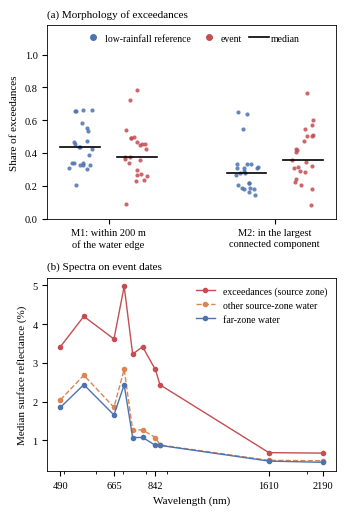

In [4]:
# NB11-17b | Figure 7 rebuilt from the saved R8 files at single-column width (3.5 in) with 7–8 pt text: (a) morphology M1 and M2 on reference and event dates with medians; (b) median spectra on event dates
MO7 = pd.read_csv(need(f'{OUT}/r8_morphology_guanabara.csv'))
SP7 = pd.read_csv(need(f'{OUT}/r8_spectra_guanabara.csv'))
BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
WL = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]
MED7 = SP7.groupby('class')[BANDS].median()
REF_C, EV_C = '#4c72b0', '#c44e52'
with mpl.rc_context({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7.5,
                     'ytick.labelsize': 7.5, 'legend.fontsize': 7}):
    fig, (a, b) = plt.subplots(2, 1, figsize=(COL1, 5.2), gridspec_kw={'height_ratios': [1, 1]})
    rng7 = np.random.default_rng(7)
    for k, m in enumerate(['M1', 'M2']):
        for role, off, colr in (('ref', -0.17, REF_C), ('event', 0.17, EV_C)):
            v = MO7[MO7.role == role][m].dropna()
            a.scatter(k + off + rng7.uniform(-0.07, 0.07, len(v)), v, s=9, color=colr, lw=0, alpha=0.85)
            a.plot([k + off - 0.12, k + off + 0.12], [v.median()] * 2, color='k', lw=1.2)
    a.set_xticks([0, 1]); a.set_xticklabels(['M1: within 200 m\nof the water edge', 'M2: in the largest\nconnected component'])
    a.set_ylim(0, 1.18); a.set_yticks(np.arange(0, 1.01, 0.2)); a.set_ylabel('Share of exceedances')
    a.set_title('(a) Morphology of exceedances', loc='left')
    a.legend(handles=[mpl.lines.Line2D([], [], ls='', marker='o', ms=4, color=REF_C, label='low-rainfall reference'),
                      mpl.lines.Line2D([], [], ls='', marker='o', ms=4, color=EV_C, label='event'),
                      mpl.lines.Line2D([], [], color='k', lw=1.2, label='median')],
             frameon=False, loc='upper center', ncol=3, handletextpad=0.2, columnspacing=0.8)
    for cls, colr, ls, lab in (('exc_src', EV_C, '-', 'exceedances (source zone)'), ('nonexc_src', '#dd8452', '--', 'other source-zone water'),
                               ('far', REF_C, '-', 'far-zone water')):
        b.plot(WL, 100 * MED7.loc[cls, BANDS].values, marker='o', ms=3, lw=1.0, ls=ls, color=colr, label=lab)
    b.set_xscale('log'); b.set_xticks([490, 665, 842, 1610, 2190]); b.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
    b.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    b.set_xlabel('Wavelength (nm)'); b.set_ylabel('Median surface reflectance (%)')
    b.set_title('(b) Spectra on event dates', loc='left'); b.legend(frameon=False, loc='upper right')
    fig.tight_layout(h_pad=1.2); FIG7 = save_fig(fig, 'fig7_morphology_spectra'); plt.show(); plt.close(fig)
log_event('fig7_rebuilt', {'paths': FIG7, 'layout': 'single column 3.5 in, 7-8 pt', 'inputs': ['r8_morphology_guanabara.csv', 'r8_spectra_guanabara.csv']})

**NB11-18** — Figure 1 — site map: stable water, source and far zones from the 20 m arrays, merged outlets (UTM 23S, km).

[11:25:50Z] saved fig1_study_areas (.pdf/.tiff/.png, 600 dpi)


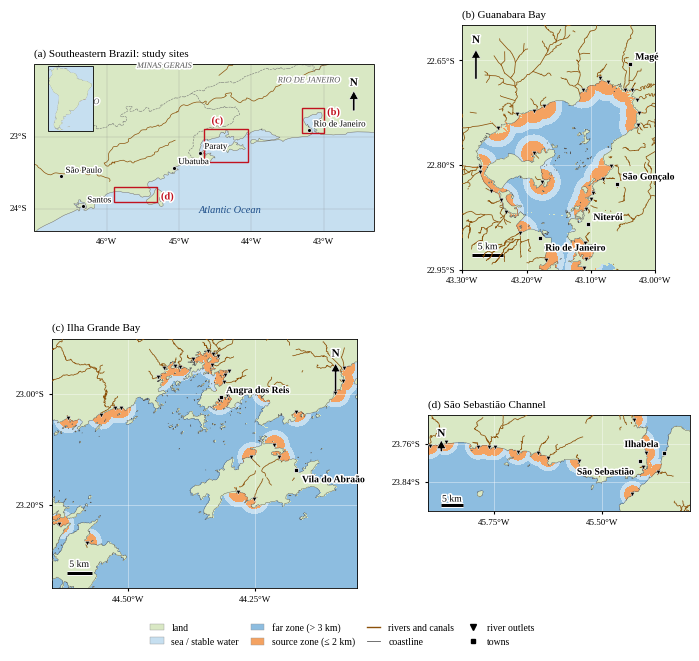

In [7]:
# NB11-18 | Figure 1 — study area (run after NB11-00, F0 and 12): regional overview and the three sites (land, water, zones, rivers, outlets, towns, lat/lon, north arrow, scale)
import subprocess, math
try:
    import cartopy.crs as ccrs, cartopy.feature as cfeature
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cartopy'], check=True)
    import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib import patheffects as pe
from pyproj import Transformer
TR = Transformer.from_crs('EPSG:4326', Q['crs'], always_xy=True)
C_LAND, C_WATER, C_FAR, C_SRC, C_RIVER, C_COAST = '#d9e8c4', '#c6dff0', '#8dbde0', '#f4a261', '#8c510a', '0.35'
HALO = [pe.withStroke(linewidth=2.2, foreground='white')]              # white halo: labels readable on land and water
# Towns: approximate town-centre coordinates (lon, lat) and label offset in points (dx, dy); verify/adjust if needed
TOWNS = {'guanabara': [('Rio de Janeiro', -43.18, -22.905, 4, -9), ('Niterói', -43.105, -22.885, 4, 3),
                       ('São Gonçalo', -43.06, -22.827, 4, 3), ('Magé', -43.04, -22.655, 4, 3)],
         'sao_sebastiao': [('São Sebastião', -45.414, -23.795, -4, -10), ('Ilhabela', -45.358, -23.778, -4, 4)],
         'ilha_grande': [('Angra dos Reis', -44.318, -23.006, 4, 3), ('Vila do Abraão', -44.169, -23.137, 4, -9)]}
REGION = [('São Paulo', -46.63, -23.55), ('Rio de Janeiro', -43.20, -22.91), ('Santos', -46.33, -23.96),
          ('Paraty', -44.71, -23.22), ('Ubatuba', -45.07, -23.43)]
ARROW = {'guanabara': (0.07, 0.78), 'ilha_grande': (0.93, 0.78), 'sao_sebastiao': (0.05, 0.62)}   # north-arrow position per panel
PANEL = {'guanabara': '(b) Guanabara Bay', 'ilha_grande': '(c) Ilha Grande Bay', 'sao_sebastiao': '(d) São Sebastião Channel'}
def lonlat_classes(site, res=0.0002):
    """Resample the 20 m UTM class arrays to a regular lon/lat grid: 0 land, 1 stable water, 2 far zone, 3 source zone."""
    S = STATIC[site]; g = grid_c(site, 20)['affineTransform']; b = SITES[site]
    lons = np.arange(b[0] + res / 2, b[2], res); lats = np.arange(b[3] - res / 2, b[1], -res)
    X, Y = TR.transform(*np.meshgrid(lons, lats))
    col = np.clip(((X - g['translateX']) / 20).astype(int), 0, S['water'].shape[1] - 1)
    row = np.clip(((g['translateY'] - Y) / 20).astype(int), 0, S['water'].shape[0] - 1)
    w, z = S['water'][row, col], S['zone'][row, col]
    return np.where(z == 1, 3, np.where(z == 2, 2, np.where(w == 1, 1, 0))).astype(np.uint8)
def deg_fmt(axis):
    f = lambda v, _: f"{abs(v):.2f}°{'W' if v < 0 else 'E'}" if axis == 'x' else f"{abs(v):.2f}°{'S' if v < 0 else 'N'}"
    return mpl.ticker.FuncFormatter(f)
def north_arrow(ax, x=0.92, y=0.80):
    ax.annotate('', xy=(x, y + 0.12), xytext=(x, y), xycoords='axes fraction',
                arrowprops=dict(facecolor='k', edgecolor='white', width=1.6, headwidth=6.5, headlength=6, lw=0.4))
    ax.text(x, y + 0.14, 'N', transform=ax.transAxes, ha='center', va='bottom', fontsize=8, weight='bold', path_effects=HALO)
def scale_bar(ax, km, lat):
    b = ax.get_xlim(), ax.get_ylim(); dlon = km / (111.32 * math.cos(math.radians(lat)))
    x0 = b[0][0] + 0.05 * (b[0][1] - b[0][0]); y0 = b[1][0] + 0.06 * (b[1][1] - b[1][0])
    ax.plot([x0, x0 + dlon], [y0, y0], color='k', lw=2.2, solid_capstyle='butt', path_effects=[pe.withStroke(linewidth=3.6, foreground='white')])
    ax.text(x0 + dlon / 2, y0 + 0.015 * (b[1][1] - b[1][0]), f'{km} km', ha='center', va='bottom', fontsize=7, path_effects=HALO)
def site_panel(ax, site):
    b = SITES[site]; cls = lonlat_classes(site)
    ax.imshow(cls, extent=[b[0], b[2], b[1], b[3]], origin='upper', interpolation='nearest',
              cmap=mpl.colors.ListedColormap([C_LAND, C_WATER, C_FAR, C_SRC]), vmin=0, vmax=3)
    raw = read_json(f'{F1}/osm_raw_{site}.json', {'coast': [], 'water': []})
    for kind, colr, lw in (('water', C_RIVER, 0.55), ('coast', C_COAST, 0.3)):
        for w in raw[kind]:
            gg = w.get('geometry', [])
            if len(gg) > 1: ax.plot([p['lon'] for p in gg], [p['lat'] for p in gg], color=colr, lw=lw, zorder=3)
    o = pd.read_csv(f'{F1}/outlets_merged_{site}.csv')
    ax.scatter(o.lon, o.lat, s=10, marker='v', color='k', edgecolor='white', lw=0.3, zorder=5)
    for name, lo, la, dx, dy in TOWNS[site]:
        ax.plot(lo, la, 's', ms=3.2, mfc='k', mec='white', mew=0.5, zorder=6)
        ax.annotate(name, (lo, la), xytext=(dx, dy), textcoords='offset points', fontsize=7, weight='semibold',
                    ha='left' if dx >= 0 else 'right', path_effects=HALO, zorder=7)
    ax.set_xlim(b[0], b[2]); ax.set_ylim(b[1], b[3]); ax.set_aspect(1 / math.cos(math.radians((b[1] + b[3]) / 2)))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3)); ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
    ax.xaxis.set_major_formatter(deg_fmt('x')); ax.yaxis.set_major_formatter(deg_fmt('y'))
    ax.tick_params(labelsize=6.5, length=2); ax.grid(color='white', lw=0.4, alpha=0.7)
    ax.set_title(PANEL[site], loc='left', fontsize=8); north_arrow(ax, *ARROW[site]); scale_bar(ax, 5, (b[1] + b[3]) / 2)
def add_ne(ax, cat, name, scale, **kw):
    """Add a Natural Earth layer only if it can be loaded (download happens here, not at save time)."""
    try:
        f = cfeature.NaturalEarthFeature(cat, name, scale); next(iter(f.geometries())); ax.add_feature(f, **kw); return True
    except Exception as ex:
        hb(f'Natural Earth {name} ({scale}) unavailable: {str(ex)[:60]}'); return False
def overview(ax):
    ext = [-47.0, -42.3, -24.3, -22.0]; ax.set_extent(ext, crs=ccrs.PlateCarree())
    add_ne(ax, 'physical', 'ocean', '10m', facecolor=C_WATER, edgecolor='none')
    add_ne(ax, 'physical', 'land', '10m', facecolor=C_LAND, edgecolor=C_COAST, lw=0.3)
    add_ne(ax, 'physical', 'rivers_lake_centerlines', '10m', facecolor='none', edgecolor=C_RIVER, lw=0.5)
    add_ne(ax, 'cultural', 'admin_1_states_provinces_lines', '10m', facecolor='none', edgecolor='0.45', lw=0.4, ls='--')
    for s, (x0, y0, x1, y1) in SITES.items():
        ax.add_patch(mpl.patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='#c1121f', lw=1.0, transform=ccrs.PlateCarree(), zorder=5))
        lx, ly, ha, va = {'guanabara': (x1 + 0.05, y1, 'left', 'top'), 'ilha_grande': (x0 + 0.1, y1 + 0.05, 'left', 'bottom'),
                          'sao_sebastiao': (x1 + 0.05, y0, 'left', 'bottom')}[s]
        ax.text(lx, ly, PANEL[s][:3], transform=ccrs.PlateCarree(), fontsize=7.5, weight='bold', color='#c1121f',
                ha=ha, va=va, path_effects=HALO, zorder=6)
    for name, lo, la in REGION:
        ax.plot(lo, la, 'o', ms=2.8, mfc='k', mec='white', mew=0.5, transform=ccrs.PlateCarree(), zorder=6)
        ax.text(lo + 0.06, la + 0.05, name, transform=ccrs.PlateCarree(), fontsize=6.5, path_effects=HALO, zorder=7)
    for name, lo, la in (('SÃO PAULO', -46.4, -22.55), ('RIO DE JANEIRO', -43.2, -22.25), ('MINAS GERAIS', -45.2, -22.05)):
        ax.text(lo, la, name, transform=ccrs.PlateCarree(), fontsize=6, style='italic', color='0.35', ha='center', path_effects=HALO)
    ax.text(-44.3, -24.05, 'Atlantic Ocean', transform=ccrs.PlateCarree(), fontsize=7.5, style='italic', color='#1d4e89', ha='center')
    gl = ax.gridlines(draw_labels=True, lw=0.3, color='0.5', alpha=0.5, xlocs=[-47, -46, -45, -44, -43], ylocs=[-24, -23, -22])
    gl.top_labels = gl.right_labels = False; gl.xlabel_style = gl.ylabel_style = {'size': 6.5}
    ax.set_title('(a) Southeastern Brazil: study sites', loc='left', fontsize=8); north_arrow(ax, 0.94, 0.72)
    ins = ax.inset_axes([0.005, 0.60, 0.2, 0.39], projection=ccrs.PlateCarree())   # locator: South America
    ins.set_extent([-82, -34, -56, 13], crs=ccrs.PlateCarree())
    if add_ne(ins, 'physical', 'land', '110m', facecolor=C_LAND, edgecolor=C_COAST, lw=0.2):
        add_ne(ins, 'physical', 'ocean', '110m', facecolor=C_WATER, edgecolor='none')
        ins.add_patch(mpl.patches.Rectangle((ext[0], ext[2]), ext[1] - ext[0], ext[3] - ext[2], fill=False, ec='#c1121f', lw=0.8,
                                            transform=ccrs.PlateCarree()))
    else:
        ins.remove()
if 'grid_c' not in globals():                                         # fast mode: grid() comes from NB11-12 (Earth Engine sign-in)
    _GRID = {}
    def grid_c(site, scale=20):
        if (site, scale) not in _GRID: _GRID[(site, scale)] = grid(site, scale)
        return _GRID[(site, scale)]
STATIC = {s: dict(np.load(need(f'{ARR}/static_{s}.npz'))) for s in SITES}
fig = plt.figure(figsize=(COL2, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.3, 1], height_ratios=[1, 1.02], hspace=0.28, wspace=0.18)
overview(fig.add_subplot(gs[0, 0], projection=ccrs.PlateCarree()))
site_panel(fig.add_subplot(gs[0, 1]), 'guanabara')
site_panel(fig.add_subplot(gs[1, 0]), 'ilha_grande')
site_panel(fig.add_subplot(gs[1, 1]), 'sao_sebastiao')
H = [mpl.patches.Patch(fc=C_LAND, ec='0.6', lw=0.3, label='land'), mpl.patches.Patch(fc=C_WATER, ec='0.6', lw=0.3, label='sea / stable water'),
     mpl.patches.Patch(fc=C_FAR, ec='0.6', lw=0.3, label='far zone (> 3 km)'), mpl.patches.Patch(fc=C_SRC, ec='0.6', lw=0.3, label='source zone (≤ 2 km)'),
     mpl.lines.Line2D([], [], color=C_RIVER, lw=1, label='rivers and canals'), mpl.lines.Line2D([], [], color=C_COAST, lw=0.6, label='coastline'),
     mpl.lines.Line2D([], [], ls='', marker='v', ms=4, color='k', label='river outlets'),
     mpl.lines.Line2D([], [], ls='', marker='s', ms=3.5, color='k', label='towns')]
fig.legend(handles=H, loc='lower center', ncol=4, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.005), handlelength=1.4, columnspacing=1.2)
fig.subplots_adjust(left=0.07, right=0.985, top=0.965, bottom=0.10)
FIG1 = save_fig(fig, 'fig1_study_areas'); plt.show(); plt.close(fig)
log_event('fig1', {'paths': FIG1, 'sources': 'JRC GSW (stable water), NB10 zones, OSM rivers/coastline (NB09 cache), merged outlets, '
                   'Natural Earth 10 m (overview)', 'towns': TOWNS})

[11:44:34Z] FDI guanabara 2023-04-13: requesting ...
[11:45:33Z] FDI guanabara 2023-03-24: requesting ...
[11:47:25Z] saved fig6_fdi_index_guanabara (.pdf/.tiff/.png, 600 dpi)


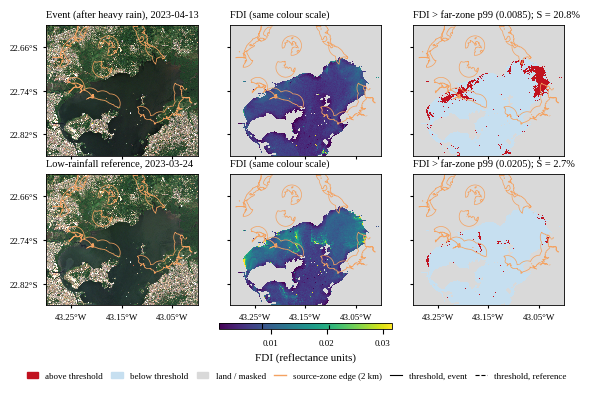

In [8]:
# NB11-20 | Figure 6 (replacement, same page footprint) — the index itself: true colour, FDI and FDI exceedances for the largest Guanabara event and its low-rainfall reference
# Run after NB11-00, F0 and 12 (Earth Engine sign-in). Uses cached true-colour and class arrays; downloads only two FDI rasters (20 m, ~12 MB each), cached.
from pyproj import Transformer
EV, RF = '2023-04-13', '2023-03-24'                                   # largest ΔS pair (Section IV-E)
CROP = [-43.30, -22.86, -43.00, -22.62]                              # northern bay with the main river mouths (lon0, lat0, lon1, lat1)
if 'grid_c' not in globals():
    _GRID = {}
    def grid_c(site, scale=20):
        if (site, scale) not in _GRID: _GRID[(site, scale)] = grid(site, scale)
        return _GRID[(site, scale)]
def fdi_array(site, d):
    p = f'{ARR}/fdi_{site}_{d}.npz'
    if os.path.exists(p): return np.load(p)['fdi']
    hb(f'FDI {site} {d}: requesting ...'); _, fdi, valid = scene(site, d)
    a = pixels(fdi.updateMask(valid).unmask(-9).toFloat().rename('fdi'), grid_c(site, 20))
    arr = np.asarray(a['fdi']).astype(np.float32); arr[arr <= -8.9] = np.nan
    np.savez_compressed(p, fdi=arr); return arr
def crop_idx(site, scale):
    g = grid_c(site, scale)['affineTransform']; T = Transformer.from_crs('EPSG:4326', Q['crs'], always_xy=True)
    xs, ys = T.transform([CROP[0], CROP[2], CROP[0], CROP[2]], [CROP[1], CROP[1], CROP[3], CROP[3]])
    c0, c1 = int((min(xs) - g['translateX']) / scale), int((max(xs) - g['translateX']) / scale)
    r0, r1 = int((g['translateY'] - max(ys)) / scale), int((g['translateY'] - min(ys)) / scale)
    return slice(max(r0, 0), r1), slice(max(c0, 0), c1)
STATIC = {'guanabara': dict(np.load(need(f'{ARR}/static_guanabara.npz')))}
def class_or_static(d):
    try: return class_array('guanabara', d)
    except NameError:                                                 # fast mode: rebuild from the cached packed band
        vx = np.load(need(f'{ARR}/vx_guanabara_{d}.npz'))['vx'] if os.path.exists(f'{ARR}/vx_guanabara_{d}.npz') else None
        if vx is None: A = dict(np.load(need(f'{ARR}/cls_guanabara_{d}.npz'))); return A
        return {'water': STATIC['guanabara']['water'], 'zone': STATIC['guanabara']['zone'], 'valid': (vx >= 1).astype(np.uint8), 'exc': (vx == 2).astype(np.uint8)}
rgb_p = lambda d: np.load(need(f'{ARR}/rgb_guanabara_{d}_10m.npz'))['rgb']
ST = {d: read_json(need(f'{F2}/statsF_guanabara_{d}.json')) for d in (EV, RF)}
r20, c20 = crop_idx('guanabara', 20); r10, c10 = crop_idx('guanabara', 10)
F = {d: fdi_array('guanabara', d)[r20, c20] for d in (EV, RF)}
A = {d: {k: v[r20, c20] for k, v in class_or_static(d).items()} for d in (EV, RF)}
vals = np.concatenate([F[d][np.isfinite(F[d])] for d in (EV, RF)])
VMIN, VMAX = np.percentile(vals, [1, 99.8])                          # one colour scale for both dates
ext = [CROP[0], CROP[2], CROP[1], CROP[3]]; asp = 1 / np.cos(np.radians(np.mean(CROP[1::2])))
cmap = mpl.colormaps['viridis'].copy(); cmap.set_bad('#d9d9d9')     # grey = land, cloud-masked or invalid
with mpl.rc_context({'font.size': 7.5, 'axes.titlesize': 7.5, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5}):
    fig = plt.figure(figsize=(COL2 - 0.2, 3.95))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.045], wspace=0.06, hspace=0.2)
    ax = np.array([[fig.add_subplot(gs[i, j]) for j in range(3)] for i in range(2)]); cax = fig.add_subplot(gs[2, 1])
    for i, (d, lab) in enumerate(((EV, 'Event (after heavy rain)'), (RF, 'Low-rainfall reference'))):
        q, S = ST[d]['thr_far_p99'], ST[d]['src']['exc_mean']
        src = (A[d]['zone'] == 1)
        ax[i, 0].imshow(rgb_p(d)[r10, c10], extent=ext, interpolation='nearest'); ax[i, 0].set_title(f'{lab}, {d}', loc='left')
        im = ax[i, 1].imshow(F[d], extent=ext, cmap=cmap, vmin=VMIN, vmax=VMAX, interpolation='nearest')
        ax[i, 1].set_title('FDI (same colour scale)', loc='left')
        exc = np.where(np.isfinite(F[d]), np.where(F[d] > q, 2, 1), 0)
        ax[i, 2].imshow(exc, extent=ext, cmap=mpl.colors.ListedColormap(['#d9d9d9', '#c6dff0', '#c1121f']), vmin=0, vmax=2, interpolation='nearest')
        ax[i, 2].set_title(f'FDI > far-zone p99 ({q:.4f}); S = {100 * S:.1f}%', loc='left')
        for a in ax[i]:
            a.contour(src, levels=[0.5], colors='#f4a261', linewidths=0.5,
                      extent=[ext[0], ext[1], ext[3], ext[2]], origin='upper')
            a.set_aspect(asp); a.tick_params(length=2)
            a.set_xticks([-43.25, -43.15, -43.05]); a.set_yticks([-22.82, -22.74, -22.66])
            a.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{abs(v):.2f}°W')); a.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{abs(v):.2f}°S'))
            if a is not ax[i, 0]: a.set_yticklabels([])
            if i == 0: a.set_xticklabels([])
    cb = fig.colorbar(im, cax=cax, orientation='horizontal')
    cb.set_label('FDI (reflectance units)'); cb.ax.tick_params(labelsize=6.5)
    for d, ls in ((EV, '-'), (RF, '--')): cb.ax.axvline(ST[d]['thr_far_p99'], color='k', lw=0.8, ls=ls)
    fig.legend(handles=[mpl.patches.Patch(color='#c1121f', label='above threshold'), mpl.patches.Patch(color='#c6dff0', label='below threshold'),
                        mpl.patches.Patch(color='#d9d9d9', label='land / masked'), mpl.lines.Line2D([], [], color='#f4a261', lw=1, label='source-zone edge (2 km)'),
                        mpl.lines.Line2D([], [], color='k', lw=0.8, label='threshold, event'), mpl.lines.Line2D([], [], color='k', lw=0.8, ls='--', label='threshold, reference')],
               loc='lower center', ncol=6, frameon=False, fontsize=6.5, bbox_to_anchor=(0.5, -0.04), handlelength=1.3, columnspacing=0.9)
    FIG6B = save_fig(fig, 'fig6_fdi_index_guanabara'); plt.show(); plt.close(fig)
log_event('fig6_fdi', {'paths': FIG6B, 'event': EV, 'reference': RF, 'crop': CROP, 'fdi_scale': [float(VMIN), float(VMAX)],
                       'S': {d: ST[d]['src']['exc_mean'] for d in (EV, RF)}, 'thr': {d: ST[d]['thr_far_p99'] for d in (EV, RF)}})

## F. Close-out

**NB11-19** — Close-out: manuscript numbers from NB11 and a manifest (SHA-256) of every NB11 output.

In [ ]:
# NB11-19 | Close-out: manuscript numbers from NB11 and a manifest (SHA-256) of every NB11 output
NUM = {'methods_audit': read_json(LOG).get('methods_audit'), 'glint_conventions': GL, 'R7': R7, 'R9': R9,
       'R8_morphology': read_json(LOG).get('R8_morphology'), 'R8_spectra': read_json(LOG).get('R8_spectra'),
       'array_qa': read_json(LOG).get('array_qa')}
write_json(f'{OUT}/nb11_numbers.json', NUM)
MAN = {os.path.relpath(os.path.join(dp, f), ROOT): {'bytes': os.path.getsize(os.path.join(dp, f)), 'sha256': sha(os.path.join(dp, f))}
       for dp, _, fs in os.walk(OUT) for f in fs if not f.endswith('.tmp') and f != 'nb11_manifest.json'}
write_json(f'{OUT}/nb11_manifest.json', MAN); log_event('close_out', {'n_files': len(MAN)})
hb(f'NB11 complete: {len(MAN)} files in {OUT}')